# Ranking models — consolidated comparison

**Question (a)**: the day before a season starts, predict the final regular-season ranking of every
team *inside its conference* (two rankings of ~15 teams per season, ordered by points).

This notebook is the **single model notebook** of the ranking project. It compares, with one
protocol:

* the naive baselines (last season's points, 3-season mean);
* team-history models (Ridge, random forest, gradient boosting, ensemble);
* pairwise learning-to-rank models (logistic, boosting, blend);
* the same models with the **external features** selected in `ranking_analysis.ipynb`
  (roster composition + shots/luck).

The old separate prediction notebooks are kept in `archive/` for traceability; everything useful
from them is re-implemented here.

> **Protocol in one line**: for each test season *Y*, train on every season `< Y` and predict *Y*
> (walk-forward). Never use information from *Y* or later.

## 1. Data and evaluation protocol

* Input: `data_prepared/teams.csv`, prepared by `data_preparation.ipynb`.
* Target: league-wide **z-score of the season points** (`target`). The predicted ranking is obtained by
  sorting the predicted scores inside each `(year, conference)`.
* Features:
  * **base** — team history and coach, selected in `ranking_analysis.ipynb`;
  * **external** — base + roster composition + shots/luck, selected in the same notebook.
  The selection is stored in `selected_features.json`.
* Test seasons: **2005–2009** (2004 is the lockout, no season). Seasons before 2005 are only used for
  design decisions in `ranking_analysis.ipynb`; the models here are trained walk-forward.
* Metrics, averaged over the 10 conference rankings (5 seasons × 2 conferences):

| Metric | Meaning | Better |
|---|---|---|
| `MAE` | mean absolute error in rank positions | lower |
| `RMSE` | root mean squared error in rank positions | lower |
| `Spearman` | rank correlation between predicted and actual ranking | higher |
| `top_overlap` | share of the 8 predicted playoff teams that really finished top 8 | higher |
| `within_2` | share of teams predicted within 2 positions of their true rank | higher |
| `pair_accuracy` | share of team pairs ordered correctly (Kendall tau rescaled to [0, 1]) | higher |

The naive reference is **last season's points** (re-ranked in the current conference). A random ranking
is shown as a floor: it has no skill but gives the scale of the metrics.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import kendalltau
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV, LogisticRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor,
    HistGradientBoostingClassifier,
    VotingRegressor,
)

# Make the helper modules importable whether the notebook is run from the project root
# or from the ranking/ directory.
for candidate in [Path.cwd(), Path.cwd() / "ranking"]:
    if (candidate / "ranking_utils.py").exists():
        sys.path.insert(0, str(candidate))
        break

import ranking_utils as ru
import ranking_features as rf

RS = ru.RANDOM_STATE
TEST_START = ru.TEST_START_YEAR

# Sober, consistent palette: naive in orange, model families in blue/green/purple.
COLORS = {
    "Naive": "#DD8452",
    "Team history": "#4C72B0",
    "Pairwise": "#55A868",
    "External": "#8172B3",
    "Reference": "#8C8C8C",
}
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titlesize": 11,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

## 2. Build the datasets

Two feature sets are used, both defined in `ranking_analysis.ipynb`:

* **base** — previous points, longer history and coach information;
* **external** — base + roster composition (top-6 forwards, top-4 defencemen, age, size,
  continuity) + shots/luck (PDO, shot differential, shooting and save percentages).

The external features are built from the raw tables (`Scoring.csv`, `Goalies.csv`, `Teams.csv`,
`Master.csv`, etc.) by `ranking_features.py`. The roster block uses the players who actually played
for the team in the season, so in-season arrivals are included; this is a mild upper bound, documented
in the analysis notebook and in the final limitations.

In [2]:
teams = ru.load_teams()
df = ru.build_dataset(teams)
groups = ru.feature_groups(df)

selection = json.loads(ru.SELECTED_FEATURES_PATH.read_text())
BASE_FEATURES = selection["base_features"]
EXT_FEATURES = selection["features"]
SELECTED_GROUPS = selection["selected_groups"]

ext, EXT_GROUPS = rf.build_external_features(ru.DATA_DIR)
n_before = len(df)
df_ext = df.merge(ext.drop(columns=["franchID"]), on=["year", "tmID"], how="left")
assert len(df_ext) == n_before, "External merge duplicated team-seasons"
EXT_COLS = [c for cols in EXT_GROUPS.values() for c in cols]
df_ext[EXT_COLS] = df_ext[EXT_COLS].fillna(0.0)

assert not df[BASE_FEATURES].isna().any().any(), "NaN in base features"
assert not df_ext[EXT_FEATURES].isna().any().any(), "NaN in external features"

EVAL_YEARS = sorted(int(y) for y in df.loc[df["year"] >= TEST_START, "year"].unique())
n_rankings = df.loc[df["year"].isin(EVAL_YEARS)].groupby(["year", "confID"]).ngroups

print(f"Team-seasons: {len(df)} | test seasons: {EVAL_YEARS}")
print(f"Conference rankings evaluated: {n_rankings}")
print(f"Selected groups: {SELECTED_GROUPS}")
print(f"Base features ({len(BASE_FEATURES)}): {BASE_FEATURES}")
print(f"External features ({len(EXT_FEATURES)}): {EXT_FEATURES}")

Team-seasons: 732 | test seasons: [2005, 2006, 2007, 2008, 2009]
Conference rankings evaluated: 10
Selected groups: ['prev_points', 'roster', 'shots_luck', 'coach']
Base features (8): ['pts_z_lag1', 'coach_changed', 'pts_z_lag2', 'pts_z_lag3', 'pts_z_lag4', 'pts_z_lag5', 'pts_z_mean3', 'pts_z_mean5']
External features (16): ['pts_z_lag1', 'top3_f_pts_z', 'top6_f_pts_z', 'top4_d_pts_z', 'roster_age_z', 'roster_size_z', 'continuity_z', 'roster_pts_z', 'sh_pct_lag1_z', 'sv_pct_lag1_z', 'pdo_lag1_z', 'shot_diff_lag1_z', 'shot_diff_pct_lag1_z', 'pdo_mean3_z', 'shot_diff_pct_mean3_z', 'coach_changed']


## 3. Models compared

All models predict a score per team; the ranking is obtained by sorting the scores inside each
`(year, conference)`. Hyper-parameters are fixed, conservative values (no tuning on the test seasons).

| Family | Model | Idea |
|---|---|---|
| Naive | Previous season | rank by last season's points |
| Naive | Mean 3 seasons | rank by the 3-season mean of points |
| Team history | Ridge | regularised linear regression (strong shrinkage) |
| Team history | Random forest | non-linear, shallow trees |
| Team history | Gradient boosting | non-linear, shallow boosting |
| Team history | Ensemble | average of Ridge, random forest and boosting |
| Pairwise | Pairwise logistic | learn P(A ahead of B) from feature differences |
| Pairwise | Pairwise boosting | non-linear version of the pairwise model |
| Pairwise | Blend | average of Ridge, pairwise logistic and pairwise boosting |
| External | Ridge + external | Ridge with base + roster + shots/luck |
| External | Gradient boosting + external | boosting with the same features |
| External | Ensemble + external | average of Ridge + external and boosting + external |
| Reference | Random ranking | random scores, fixed seed (floor, no skill) |

In [3]:
# ---- model factories -------------------------------------------------------
ridge = lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30)))
random_forest = lambda: RandomForestRegressor(
    n_estimators=300, min_samples_leaf=10, max_features=0.5,
    random_state=RS, n_jobs=-1,
)
boosting = lambda: HistGradientBoostingRegressor(
    max_depth=3, learning_rate=0.03, max_iter=250,
    min_samples_leaf=20, l2_regularization=1.0, random_state=RS,
)

TEAM_MODELS = {
    "Ridge": ridge,
    "Random forest": random_forest,
    "Gradient boosting": boosting,
    "Ensemble (mean)": lambda: VotingRegressor([
        ("ridge", ridge()), ("rf", random_forest()), ("gbm", boosting()),
    ]),
}

PAIRWISE_MODELS = {
    "Pairwise logistic": lambda: make_pipeline(
        StandardScaler(with_mean=False),
        LogisticRegression(C=0.1, fit_intercept=False, max_iter=2000),
    ),
    "Pairwise boosting": lambda: HistGradientBoostingClassifier(
        max_depth=3, learning_rate=0.05, max_iter=150,
        min_samples_leaf=50, l2_regularization=1.0, random_state=RS,
    ),
}

EXTERNAL_MODELS = {
    "Ridge + external": ridge,
    "Gradient boosting + external": boosting,
    "Ensemble + external": lambda: VotingRegressor([
        ("ridge", ridge()), ("gbm", boosting()),
    ]),
}

NAIVE = {
    "Naive: previous season": "pts_z_lag1",
    "Naive: mean 3 seasons": "pts_z_mean3",
}

FAMILY = {}
FAMILY.update({name: "Naive" for name in NAIVE})
FAMILY.update({name: "Team history" for name in TEAM_MODELS})
FAMILY.update({name: "Pairwise" for name in PAIRWISE_MODELS})
FAMILY["Blend (ridge + pairwise)"] = "Pairwise"
FAMILY.update({name: "External" for name in EXTERNAL_MODELS})
FAMILY["Random ranking"] = "Reference"

## 4. Walk-forward evaluation

For every test season *Y*: fit on all seasons `< Y`, predict *Y*. Team-history and pairwise models
use the **base** features; external models use the **base + external** features. The pairwise models
build all within-conference pairs of the training seasons and score all ordered pairs of the test
season; the blend averages the within-conference z-scores of Ridge and the two pairwise models.

In [4]:
# ---- pairwise ranker -------------------------------------------------------
def pair_differences(group, features):
    '''Feature differences (better team - worse team) for all unordered pairs.'''
    X = group[features].to_numpy(float)
    rank = group["conf_rank"].to_numpy()
    i, j = np.triu_indices(len(group), k=1)
    better_first = rank[i] < rank[j]
    better = np.where(better_first, i, j)
    worse = np.where(better_first, j, i)
    return X[better] - X[worse]


class PairwiseRanker:
    def __init__(self, make_classifier):
        self.make_classifier = make_classifier

    def fit(self, train, features):
        self.features = features
        diffs = [
            pair_differences(g, features)
            for (_, conf), g in train.groupby(["year", "confID"])
            if conf != "NONE" and len(g) >= 2
        ]
        D = np.vstack(diffs)
        X = np.vstack([D, -D])
        y = np.r_[np.ones(len(D)), np.zeros(len(D))]
        self.clf = self.make_classifier().fit(X, y)
        return self

    def score(self, test):
        scores = pd.Series(0.0, index=test.index)
        for _, g in test.groupby(["year", "confID"]):
            n = len(g)
            if n < 2:
                continue
            X = g[self.features].to_numpy(float)
            i, j = np.where(~np.eye(n, dtype=bool))
            d = X[i] - X[j]
            p = (self.clf.predict_proba(d)[:, 1] + 1 - self.clf.predict_proba(-d)[:, 1]) / 2
            scores.loc[g.index] = np.bincount(i, weights=p, minlength=n) / (n - 1)
        return scores


def walk_forward_pairwise(data, make_classifier, features, eval_years):
    outputs = []
    for year in eval_years:
        train = data[(data["year"] < year) & (data["n_hist"] >= 1)]
        test = data[data["year"] == year]
        if test.empty:
            continue
        ranker = PairwiseRanker(make_classifier).fit(train, features)
        out = test[["year", "tmID", "confID"]].copy()
        out["score"] = ranker.score(test)
        outputs.append(out)
    return pd.concat(outputs, ignore_index=True)


def within_group_z(pred):
    g = pred.set_index(["year", "tmID"])[["confID", "score"]].copy()
    grouped = g.groupby(["year", "confID"])["score"]
    z = (g["score"] - grouped.transform("mean")) / grouped.transform("std").replace(0, np.nan)
    return z.fillna(0.0)


# ---- predictions -----------------------------------------------------------
preds = {name: ru.baseline_scores(df, col, EVAL_YEARS) for name, col in NAIVE.items()}

rng = np.random.default_rng(RS)
random_pred = df.loc[df["year"].isin(EVAL_YEARS), ["year", "tmID", "confID"]].copy()
random_pred["score"] = rng.normal(size=len(random_pred))
preds["Random ranking"] = random_pred

for name, factory in TEAM_MODELS.items():
    preds[name] = ru.walk_forward(df, factory, BASE_FEATURES, EVAL_YEARS)

for name, factory in PAIRWISE_MODELS.items():
    preds[name] = walk_forward_pairwise(df, factory, BASE_FEATURES, EVAL_YEARS)

blend = preds["Ridge"].set_index(["year", "tmID"])[["confID"]].copy()
blend["score"] = sum(
    within_group_z(preds[p]).reindex(blend.index)
    for p in ["Ridge", "Pairwise logistic", "Pairwise boosting"]
) / 3
preds["Blend (ridge + pairwise)"] = blend.reset_index()

for name, factory in EXTERNAL_MODELS.items():
    preds[name] = ru.walk_forward(df_ext, factory, EXT_FEATURES, EVAL_YEARS)

print(f"{len(preds)} models evaluated.")

13 models evaluated.


## 5. Global results

The table is sorted by MAE. `ΔMAE vs naive` is positive when the model beats the naive
*previous season* baseline; the 95% confidence interval comes from a paired bootstrap that resamples
whole `(season, conference)` rankings (2000 draws). A model is marked **significant** only when the
whole interval is above 0.

In [5]:
def pair_accuracy(r):
    taus = [
        kendalltau(g["pred_rank"], g["conf_rank"])[0]
        for _, g in r.groupby(["year", "confID"])
    ]
    return (1 + np.mean(taus)) / 2


ranked = {name: ru.rank_predictions(pred, df) for name, pred in preds.items()}
season_tables = {name: ru.season_metrics(r) for name, r in ranked.items()}

summary = pd.DataFrame({
    name: ru.summarise(table) for name, table in season_tables.items()
}).T
summary["pair_accuracy"] = pd.Series({name: pair_accuracy(r) for name, r in ranked.items()})
summary["family"] = pd.Series(FAMILY)
summary = summary.sort_values(["mae", "spearman"], ascending=[True, False])

# Paired bootstrap against the naive previous-season baseline.
key = ["year", "tmID"]
base = ranked["Naive: previous season"].set_index(key).sort_index()
groups_id = (base["confID"] + "-" + base.index.get_level_values("year").astype(str)).to_numpy()
abs_err = {
    name: r.set_index(key).sort_index()["abs_err"].reindex(base.index).to_numpy()
    for name, r in ranked.items()
}

rows = []
for name in summary.index:
    if name == "Naive: previous season":
        gain, lo, hi, significant = 0.0, 0.0, 0.0, False
    else:
        gain, (lo, hi) = ru.paired_bootstrap(
            base["abs_err"].to_numpy(), abs_err[name], groups_id
        )
        significant = lo > 0
    rows.append({
        "model": name,
        "mae_gain_vs_naive": gain,
        "ci_low": lo,
        "ci_high": hi,
        "significant": significant,
    })

significance = pd.DataFrame(rows).set_index("model").loc[summary.index]
summary["mae_gain_vs_naive"] = significance["mae_gain_vs_naive"]
summary["ci_low"] = significance["ci_low"]
summary["ci_high"] = significance["ci_high"]
summary["significant"] = significance["significant"]

best_overall = summary.drop(index=["Random ranking"]).index[0]
random_mae = summary.loc["Random ranking", "mae"]

table = summary[["family", "mae", "rmse", "spearman", "top_overlap", "within_2",
                 "pair_accuracy", "mae_gain_vs_naive", "ci_low", "ci_high", "significant"]].copy()
table.columns = ["Family", "MAE", "RMSE", "Spearman", "Top-8", "Within 2", "Pair acc.",
                 "ΔMAE vs naive", "CI low", "CI high", "Significant"]
table["95% CI"] = table.apply(
    lambda r: f"[{r['CI low']:+.2f}, {r['CI high']:+.2f}]", axis=1
)
table = table.drop(columns=["CI low", "CI high"])
table["Significant"] = table["Significant"].map({True: "yes", False: "no"})

styled = (
    table.style
    .format({
        "MAE": "{:.3f}", "RMSE": "{:.3f}", "Spearman": "{:.3f}",
        "Top-8": "{:.3f}", "Within 2": "{:.3f}", "Pair acc.": "{:.3f}",
        "ΔMAE vs naive": "{:+.3f}",
    })
    .apply(
        lambda row: [
            "font-weight: 700" if row.name == best_overall else
            "background-color: #FAFAFA" if row.name.startswith("Naive") else ""
            for _ in row
        ],
        axis=1,
    )
    .map(
        lambda value: "color: #2E7D32; font-weight: 600" if value == "yes" else "color: #9E9E9E",
        subset=["Significant"],
    )
    .set_properties(subset=["Family", "95% CI"], **{"white-space": "nowrap"})
)
display(styled)

print(f"Random ranking reference: MAE {random_mae:.2f} | "
      f"top-8 overlap {summary.loc['Random ranking', 'top_overlap']:.2f} | "
      f"pair accuracy {summary.loc['Random ranking', 'pair_accuracy']:.2f}")
print(f"Best model: {best_overall} | MAE {summary.loc[best_overall, 'mae']:.3f} | "
      f"gain vs naive {summary.loc[best_overall, 'mae_gain_vs_naive']:+.3f} "
      f"[{summary.loc[best_overall, 'ci_low']:+.3f}, {summary.loc[best_overall, 'ci_high']:+.3f}]")

,Family,MAE,RMSE,Spearman,Top-8,Within 2,Pair acc.,ΔMAE vs naive,Significant,95% CI
Gradient boosting + external,External,2.853,3.819,0.583,0.686,0.573,0.718,+0.533,yes,"[+0.25, +0.79]"
Ensemble + external,External,3.027,3.954,0.557,0.700,0.540,0.703,+0.360,yes,"[+0.07, +0.64]"
Ridge + external,External,3.080,3.911,0.570,0.686,0.553,0.703,+0.307,yes,"[+0.05, +0.55]"
Naive: previous season,Naive,3.387,4.259,0.486,0.643,0.453,0.678,+0.000,no,"[+0.00, +0.00]"
Pairwise boosting,Pairwise,3.427,4.252,0.495,0.600,0.420,0.676,-0.040,no,"[-0.24, +0.17]"
Blend (ridge + pairwise),Pairwise,3.427,4.263,0.494,0.586,0.427,0.679,-0.040,no,"[-0.23, +0.15]"
Ridge,Team history,3.467,4.301,0.481,0.571,0.420,0.677,-0.080,no,"[-0.29, +0.12]"
Pairwise logistic,Pairwise,3.533,4.347,0.472,0.571,0.427,0.674,-0.147,no,"[-0.41, +0.09]"
Random forest,Team history,3.560,4.378,0.467,0.571,0.400,0.672,-0.173,no,"[-0.40, +0.08]"
Ensemble (mean),Team history,3.600,4.321,0.480,0.571,0.393,0.677,-0.213,no,"[-0.55, +0.09]"


Random ranking reference: MAE 4.95 | top-8 overlap 0.54 | pair accuracy 0.49
Best model: Gradient boosting + external | MAE 2.853 | gain vs naive +0.533 [+0.253, +0.787]


## 6. Models vs the naive baseline

Each dot is a model; the dashed line is the naive *previous season* baseline. A dot left of the line
(MAE) or right of it (Spearman, top-8 overlap) is better than the naive model. The random ranking is
kept in the table only, to keep the figure readable.

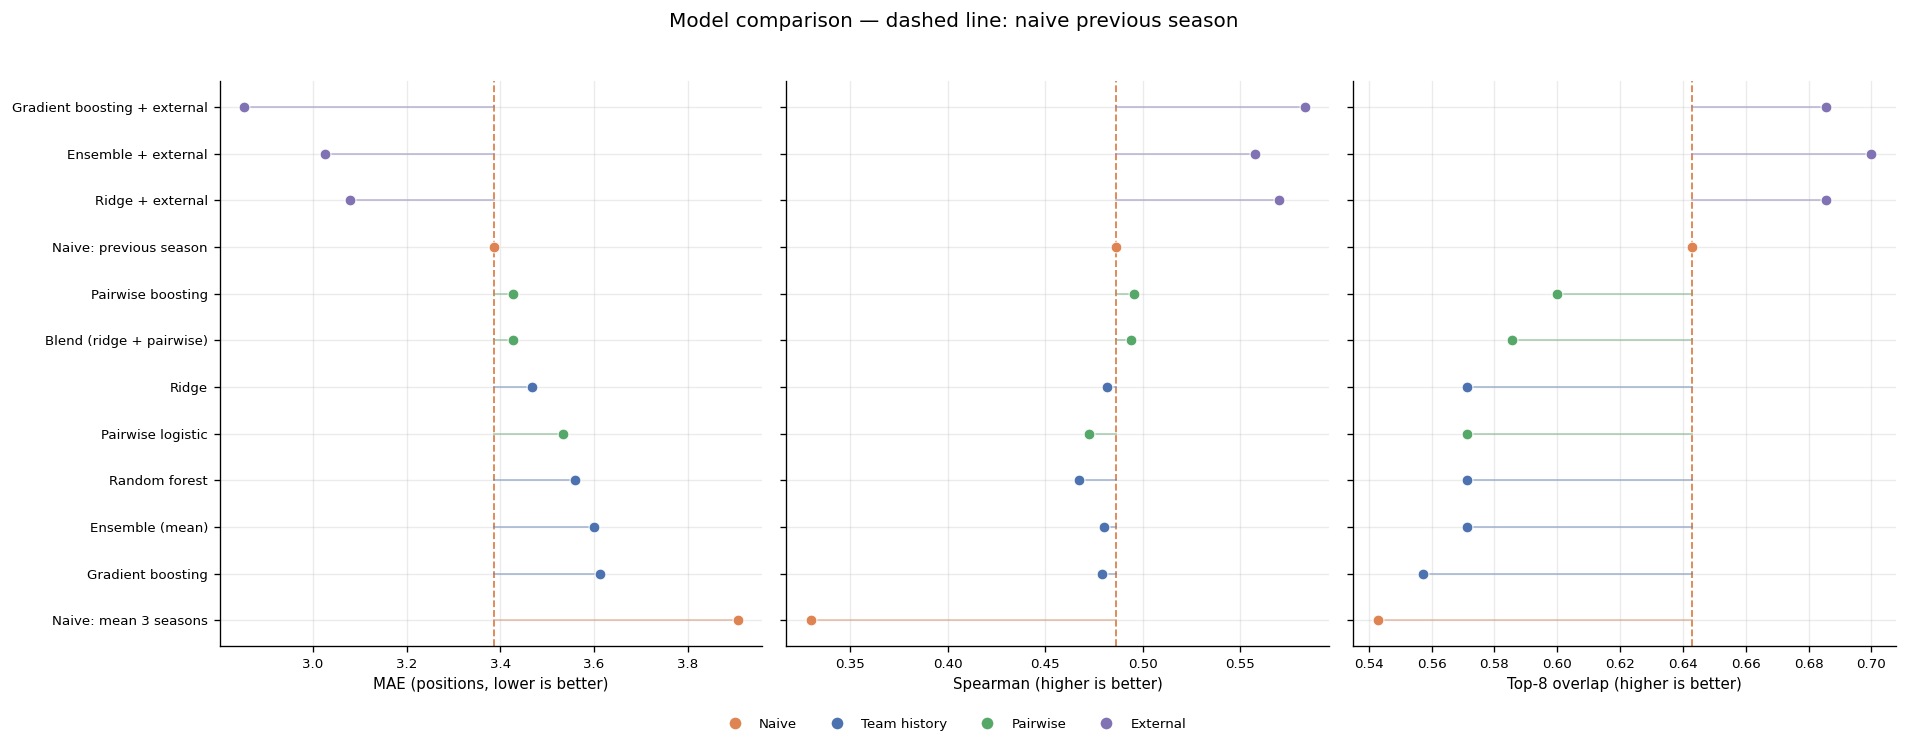

In [6]:
order = [name for name in summary.index if name != "Random ranking"]

fig, axes = plt.subplots(1, 3, figsize=(16, 6), sharey=True)
metrics = [
    ("mae", "MAE (positions, lower is better)"),
    ("spearman", "Spearman (higher is better)"),
    ("top_overlap", "Top-8 overlap (higher is better)"),
]

for ax, (metric, label) in zip(axes, metrics):
    ref = summary.loc["Naive: previous season", metric]
    values = summary.loc[order, metric]
    y = np.arange(len(order))
    for yi, (name, value) in zip(y, values.items()):
        color = COLORS[FAMILY[name]]
        ax.plot([ref, value], [yi, yi], color=color, lw=1.1, alpha=0.45, zorder=1)
        ax.scatter(value, yi, color=color, s=42, edgecolor="white", linewidth=0.6, zorder=2)
    ax.axvline(ref, color=COLORS["Naive"], ls="--", lw=1.1, zorder=0)
    ax.set_xlabel(label)
    ax.grid(axis="x", alpha=0.25)

axes[0].set_yticks(np.arange(len(order)))
axes[0].set_yticklabels(order)
axes[0].invert_yaxis()

handles = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor=COLORS[f],
           markersize=8, label=f)
    for f in ["Naive", "Team history", "Pairwise", "External"]
]
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False,
           bbox_to_anchor=(0.5, -0.015))
fig.suptitle("Model comparison — dashed line: naive previous season", y=1.00)
plt.tight_layout(rect=(0, 0.03, 1, 0.98))
plt.show()

### Is the gain statistically real?

Same comparison, but focused on the **gain in MAE** over the naive baseline with its 95% bootstrap
interval. Filled markers have an interval that excludes 0; hollow markers are within noise.

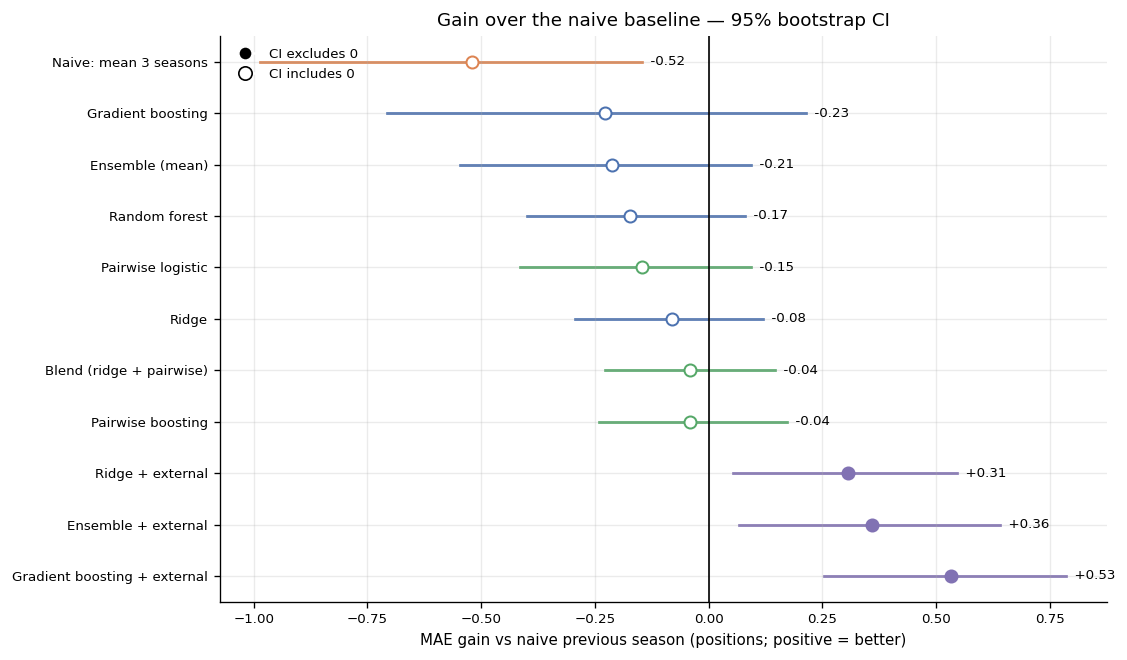

In [7]:
sig = significance.drop(index=["Naive: previous season", "Random ranking"]).copy()
sig["family"] = [FAMILY[name] for name in sig.index]
sig = sig.sort_values("mae_gain_vs_naive")

fig, ax = plt.subplots(figsize=(9.5, 5.6))
y = np.arange(len(sig))
for yi, (name, row) in zip(y, sig.iterrows()):
    color = COLORS[row["family"]]
    ax.plot([row["ci_low"], row["ci_high"]], [yi, yi], color=color, lw=1.6, zorder=1)
    face = color if row["significant"] else "white"
    ax.scatter(row["mae_gain_vs_naive"], yi, color=face, edgecolor=color,
               s=52, linewidth=1.2, zorder=2)
    ax.text(row["ci_high"], yi, f"  {row['mae_gain_vs_naive']:+.2f}",
            va="center", fontsize=8)

ax.axvline(0, color="black", lw=1)
ax.set_yticks(y)
ax.set_yticklabels(sig.index)
ax.invert_yaxis()
ax.set_xlabel("MAE gain vs naive previous season (positions; positive = better)")
ax.set_title("Gain over the naive baseline — 95% bootstrap CI")
ax.grid(axis="x", alpha=0.25)

handles = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor="black", markersize=8,
           label="CI excludes 0"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="white",
           markeredgecolor="black", markersize=8, label="CI includes 0"),
]
ax.legend(handles=handles, loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

## 7. Models vs each other

### Pairwise scorecard

Every pair of models is compared with the same paired bootstrap. For each model we count how many
other models it **significantly beats** (CI above 0) and how many **significantly beat it** (CI below 0).
The remaining comparisons are within noise.

In [8]:
models = [name for name in summary.index if name != "Random ranking"]

rows = []
for model in models:
    for opponent in models:
        if model == opponent:
            continue
        gain, (lo, hi) = ru.paired_bootstrap(
            abs_err[opponent], abs_err[model], groups_id
        )
        rows.append({
            "model": model,
            "opponent": opponent,
            "gain": gain,
            "ci_low": lo,
            "ci_high": hi,
            "better": lo > 0,
            "worse": hi < 0,
        })

head_to_head = pd.DataFrame(rows)
scorecard = head_to_head.groupby("model").agg(
    significantly_better=("better", "sum"),
    significantly_worse=("worse", "sum"),
    comparisons=("opponent", "count"),
)
scorecard["within_noise"] = (
    scorecard["comparisons"] - scorecard["significantly_better"] - scorecard["significantly_worse"]
)
scorecard = scorecard.loc[models]
scorecard.columns = ["Beats", "Loses to", "Comparisons", "Within noise"]
display(scorecard.style
        .format("{:.0f}")
        .bar(subset=["Beats"], color="#C8E6C9", vmin=0, vmax=len(models))
        .bar(subset=["Loses to"], color="#FFCDD2", vmin=0, vmax=len(models)))

,Beats,Loses to,Comparisons,Within noise
model,,,,
Gradient boosting + external,11,0,11,0
Ensemble + external,9,1,11,1
Ridge + external,9,1,11,1
Naive: previous season,1,3,11,7
Pairwise boosting,3,3,11,5
Blend (ridge + pairwise),3,3,11,5
Ridge,1,3,11,7
Pairwise logistic,1,3,11,7
Random forest,1,5,11,5


### Family champions, head to head

The best model of each family (plus the naive baseline) compared with each other. The cell value is
the **MAE gain of the row over the column** (positive = row is better); `*` means the 95% interval
excludes 0. This is the compact view of the main story.

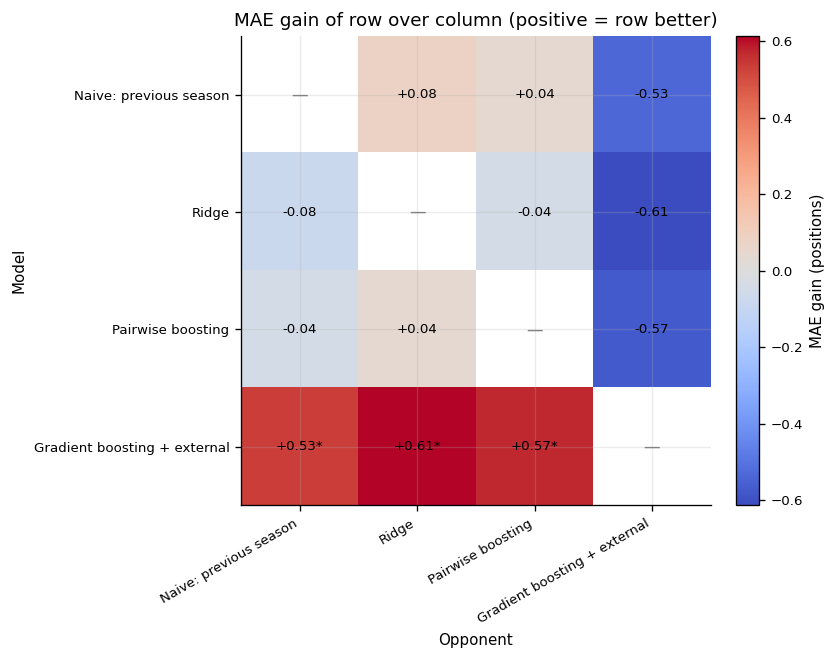

In [9]:
family_order = ["Naive", "Team history", "Pairwise", "External"]
family_rows = [
    summary[(summary["family"] == family) & (summary.index != "Random ranking")].index[0]
    for family in family_order
]
family_best = summary.loc[family_rows]
champions = list(family_best.index)

matrix = pd.DataFrame(np.nan, index=champions, columns=champions)
annotations = pd.DataFrame("", index=champions, columns=champions)

for row in champions:
    for col in champions:
        if row == col:
            continue
        rec = head_to_head[(head_to_head["model"] == row) & (head_to_head["opponent"] == col)]
        if rec.empty:
            continue
        rec = rec.iloc[0]
        matrix.loc[row, col] = rec["gain"]
        annotations.loc[row, col] = f"{rec['gain']:+.2f}" + ("*" if rec["better"] else "")

fig, ax = plt.subplots(figsize=(7.2, 5.6))
vmax = np.nanmax(np.abs(matrix.to_numpy()))
im = ax.imshow(matrix.to_numpy(), cmap="coolwarm", vmin=-vmax, vmax=vmax)
ax.set_xticks(range(len(champions)))
ax.set_xticklabels(champions, rotation=30, ha="right")
ax.set_yticks(range(len(champions)))
ax.set_yticklabels(champions)
for i in range(len(champions)):
    for j in range(len(champions)):
        if i == j:
            ax.text(j, i, "—", ha="center", va="center", color="0.5")
        else:
            ax.text(j, i, annotations.iloc[i, j], ha="center", va="center", fontsize=8)
ax.set_title("MAE gain of row over column (positive = row better)")
ax.set_xlabel("Opponent")
ax.set_ylabel("Model")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="MAE gain (positions)")
plt.tight_layout()
plt.show()

## 8. Stability across seasons and error distribution

A model can win on average and still be irregular. The left panel shows the MAE per test season for
the family champions; the right panel shows the distribution of absolute rank errors over all teams.

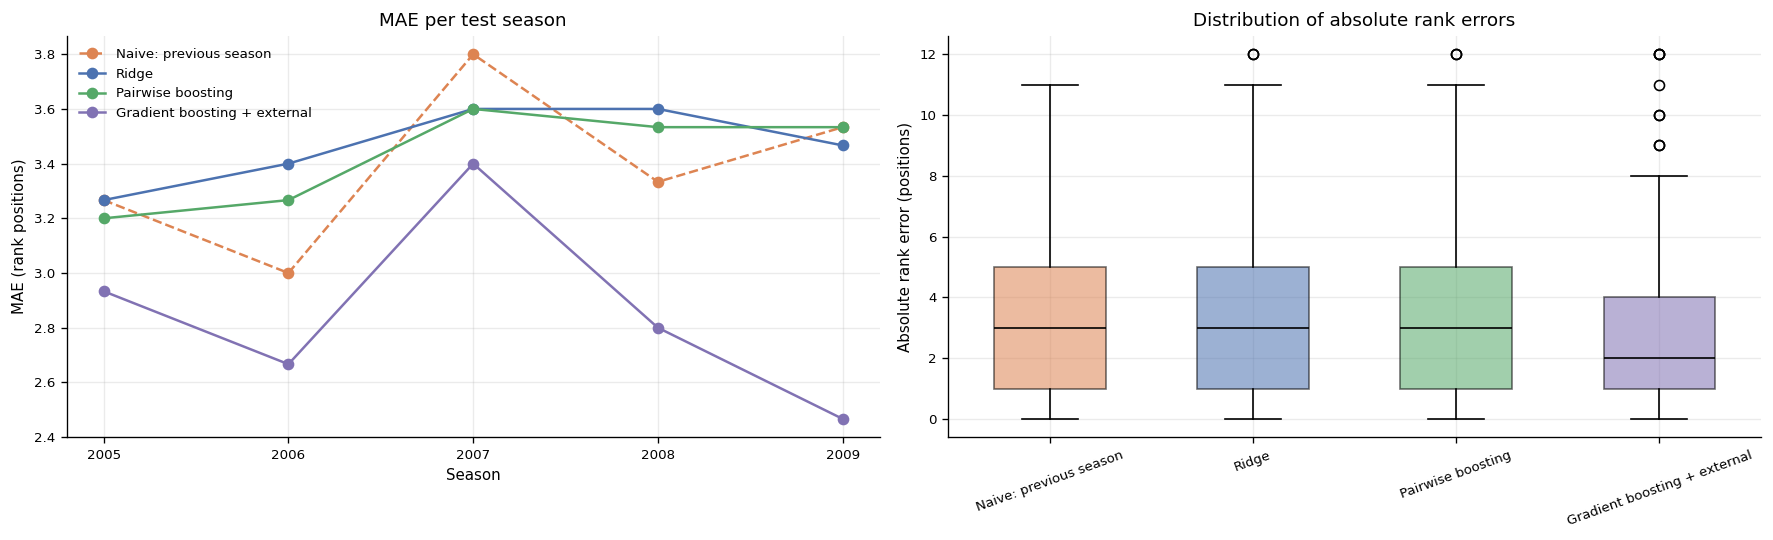

In [10]:
focus = ["Naive: previous season"] + [
    name for name in family_best.index if name != "Naive: previous season"
]
focus = list(dict.fromkeys(focus))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))

per_year = pd.DataFrame({
    name: season_tables[name].groupby("year")["mae"].mean() for name in focus
})
for name in focus:
    axes[0].plot(
        per_year.index, per_year[name], marker="o",
        ls="--" if name.startswith("Naive") else "-",
        color=COLORS[FAMILY[name]], label=name,
    )
axes[0].set_xlabel("Season")
axes[0].set_ylabel("MAE (rank positions)")
axes[0].set_xticks(per_year.index)
axes[0].set_xticklabels(per_year.index.astype(int))
axes[0].set_title("MAE per test season")
axes[0].legend(frameon=False, fontsize=8)
axes[0].grid(alpha=0.25)

box = axes[1].boxplot(
    [ranked[name]["abs_err"] for name in focus],
    tick_labels=focus, patch_artist=True, widths=0.55,
)
for patch, name in zip(box["boxes"], focus):
    patch.set_facecolor(COLORS[FAMILY[name]])
    patch.set_alpha(0.55)
for median in box["medians"]:
    median.set_color("black")
axes[1].set_ylabel("Absolute rank error (positions)")
axes[1].set_title("Distribution of absolute rank errors")
axes[1].tick_params(axis="x", rotation=20)
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

## 9. The naive family: which history window?

`ranking_analysis.ipynb` compared parameter-free history scores on seasons before 2005. Here is the
same test on the **test seasons**, which checks that the conclusion holds out of sample. These are the
baselines the models have to beat; last season is the strongest naive score.

In [11]:
windows = {
    "Last season": "pts_z_lag1",
    "Mean 2 seasons": "pts_z_mean2",
    "Mean 3 seasons": "pts_z_mean3",
    "Mean 5 seasons": "pts_z_mean5",
    "Exp. decay (0.5)": "pts_z_ewm",
}

window_table = pd.DataFrame({
    name: ru.summarise(ru.season_metrics(
        ru.rank_predictions(ru.baseline_scores(df, col, EVAL_YEARS), df)
    ))
    for name, col in windows.items()
}).T.sort_values("mae")

display(window_table.round(3))

dev = df[(df["year"] < TEST_START) & (df["n_hist"] >= 1)]
slope, intercept = np.polyfit(dev["pts_z_lag1"], dev["target"], 1)
persistence = pd.DataFrame({
    "lag": [f"lag {k}" for k in range(1, ru.LAGS + 1)],
    "spearman": [
        dev.loc[dev["n_hist"] >= k, "target"].corr(
            dev.loc[dev["n_hist"] >= k, f"pts_z_lag{k}"], method="spearman"
        )
        for k in range(1, ru.LAGS + 1)
    ],
})
print("Persistence of the standings on seasons < 2005:")
display(persistence.round(3).set_index("lag").T)
print(f"Mean reversion: target = {intercept:.3f} + {slope:.3f} × previous points z-score")
print(f"-> only about {slope:.0%} of last season's deviation from the league average is kept.")

,mae,rmse,spearman,top_overlap,within_2
Last season,3.387,4.259,0.486,0.643,0.453
Mean 2 seasons,3.693,4.532,0.420,0.543,0.387
Exp. decay (0.5),3.707,4.551,0.419,0.557,0.393
Mean 3 seasons,3.907,4.892,0.330,0.543,0.427
Mean 5 seasons,4.200,5.296,0.229,0.514,0.413


Persistence of the standings on seasons < 2005:


lag,lag 1,lag 2,lag 3,lag 4,lag 5
spearman,0.587,0.502,0.385,0.293,0.158


Mean reversion: target = 0.024 + 0.601 × previous points z-score
-> only about 60% of last season's deviation from the league average is kept.


## 10. Extended backtest: more origins (1995–2009)

The clean test (2005–2009) has only 10 conference rankings, so the confidence intervals are wide.
To check whether the conclusions are stable — and to gain statistical power — the same fixed models
are evaluated on every season from 1995 to 2009 (28 conference rankings, 2004 lockout excluded).

**Important caveat.** Seasons 1995–2004 were used in `ranking_analysis.ipynb` to select the feature
groups, so this backtest is *not* a fully clean out-of-sample test for the feature selection. It is a
**stability and power check**: the models are still trained walk-forward and never see the season they
predict, and the comparison between model families remains informative. The clean test remains
2005–2009 (section 5).

In [12]:
BACKTEST_YEARS = [y for y in range(1995, 2010) if y != 2004]


def run_all_models(eval_years):
    preds = {name: ru.baseline_scores(df, col, eval_years) for name, col in NAIVE.items()}

    rng = np.random.default_rng(RS)
    random_pred = df.loc[df["year"].isin(eval_years), ["year", "tmID", "confID"]].copy()
    random_pred["score"] = rng.normal(size=len(random_pred))
    preds["Random ranking"] = random_pred

    for name, factory in TEAM_MODELS.items():
        preds[name] = ru.walk_forward(df, factory, BASE_FEATURES, eval_years)
    for name, factory in PAIRWISE_MODELS.items():
        preds[name] = walk_forward_pairwise(df, factory, BASE_FEATURES, eval_years)

    blend = preds["Ridge"].set_index(["year", "tmID"])[["confID"]].copy()
    blend["score"] = sum(
        within_group_z(preds[p]).reindex(blend.index)
        for p in ["Ridge", "Pairwise logistic", "Pairwise boosting"]
    ) / 3
    preds["Blend (ridge + pairwise)"] = blend.reset_index()

    for name, factory in EXTERNAL_MODELS.items():
        preds[name] = ru.walk_forward(df_ext, factory, EXT_FEATURES, eval_years)

    return {name: ru.rank_predictions(pred, df) for name, pred in preds.items()}


ranked_bt = run_all_models(BACKTEST_YEARS)
tables_bt = {name: ru.season_metrics(r) for name, r in ranked_bt.items()}
summary_bt = pd.DataFrame({name: ru.summarise(t) for name, t in tables_bt.items()}).T
summary_bt["pair_accuracy"] = pd.Series({name: pair_accuracy(r) for name, r in ranked_bt.items()})
summary_bt["family"] = pd.Series(FAMILY)
summary_bt = summary_bt.sort_values(["mae", "spearman"], ascending=[True, False])

key = ["year", "tmID"]
base_bt = ranked_bt["Naive: previous season"].set_index(key).sort_index()
gid_bt = (base_bt["confID"] + "-" + base_bt.index.get_level_values("year").astype(str)).to_numpy()
abs_err_bt = {
    name: r.set_index(key).sort_index()["abs_err"].reindex(base_bt.index).to_numpy()
    for name, r in ranked_bt.items()
}

rows = []
for name in summary_bt.index:
    if name == "Naive: previous season":
        gain, lo, hi, significant = 0.0, 0.0, 0.0, False
    else:
        gain, (lo, hi) = ru.paired_bootstrap(
            base_bt["abs_err"].to_numpy(), abs_err_bt[name], gid_bt
        )
        significant = lo > 0
    rows.append({
        "model": name, "mae_gain_vs_naive": gain,
        "ci_low": lo, "ci_high": hi, "significant": significant,
    })

sig_bt = pd.DataFrame(rows).set_index("model").loc[summary_bt.index]
for col in ["mae_gain_vs_naive", "ci_low", "ci_high", "significant"]:
    summary_bt[col] = sig_bt[col]

n_rankings_bt = ranked_bt["Ridge"].groupby(["year", "confID"]).ngroups
bt_best = summary_bt.drop(index=["Random ranking"]).index[0]

bt_table = summary_bt[["family", "mae", "spearman", "top_overlap",
                       "mae_gain_vs_naive", "ci_low", "ci_high", "significant"]].copy()
bt_table.columns = ["Family", "MAE", "Spearman", "Top-8", "ΔMAE vs naive",
                    "CI low", "CI high", "Significant"]
bt_table["95% CI"] = bt_table.apply(
    lambda r: f"[{r['CI low']:+.2f}, {r['CI high']:+.2f}]", axis=1
)
bt_table = bt_table.drop(columns=["CI low", "CI high"])
bt_table["Significant"] = bt_table["Significant"].map({True: "yes", False: "no"})

print(f"Backtest origins: {BACKTEST_YEARS[0]}-{BACKTEST_YEARS[-1]} | "
      f"{n_rankings_bt} conference rankings")
print(f"Naive MAE: {summary_bt.loc['Naive: previous season', 'mae']:.3f} | "
      f"best: {bt_best} ({summary_bt.loc[bt_best, 'mae']:.3f})")
display(
    bt_table.style
    .format({
        "MAE": "{:.3f}", "Spearman": "{:.3f}", "Top-8": "{:.3f}",
        "ΔMAE vs naive": "{:+.3f}",
    })
    .apply(
        lambda row: ["font-weight: 700" if row.name == bt_best else "" for _ in row],
        axis=1,
    )
    .map(
        lambda value: "color: #2E7D32; font-weight: 600" if value == "yes" else "color: #9E9E9E",
        subset=["Significant"],
    )
    .set_properties(subset=["Family", "95% CI"], **{"white-space": "nowrap"})
)

Backtest origins: 1995-2009 | 28 conference rankings
Naive MAE: 3.076 | best: Ridge + external (2.473)


,Family,MAE,Spearman,Top-8,ΔMAE vs naive,Significant,95% CI
Ridge + external,External,2.473,0.689,0.745,+0.600,yes,"[+0.42, +0.79]"
Ensemble + external,External,2.541,0.673,0.734,+0.541,yes,"[+0.37, +0.72]"
Gradient boosting + external,External,2.574,0.661,0.711,+0.516,yes,"[+0.34, +0.71]"
Blend (ridge + pairwise),Pairwise,2.860,0.600,0.678,+0.213,yes,"[+0.04, +0.40]"
Ridge,Team history,2.861,0.597,0.673,+0.208,yes,"[+0.03, +0.40]"
Pairwise boosting,Pairwise,2.878,0.593,0.677,+0.199,yes,"[+0.01, +0.38]"
Pairwise logistic,Pairwise,2.898,0.592,0.667,+0.174,no,"[-0.03, +0.38]"
Ensemble (mean),Team history,2.925,0.588,0.672,+0.149,no,"[-0.07, +0.38]"
Random forest,Team history,2.969,0.565,0.666,+0.109,no,"[-0.07, +0.30]"
Gradient boosting,Team history,2.975,0.579,0.667,+0.099,no,"[-0.18, +0.36]"


### Effect size and confidence intervals: clean test vs backtest

The same models, same order, same bootstrap. The extended backtest has more origins, so the intervals
are narrower and the best models become significantly better than the naive baseline. This shows that
the “not significant” result of 2005–2009 is partly a **power** issue, not necessarily an absence of
effect. The clean test remains the reference because the backtest shares its feature-selection years
with `ranking_analysis.ipynb`.

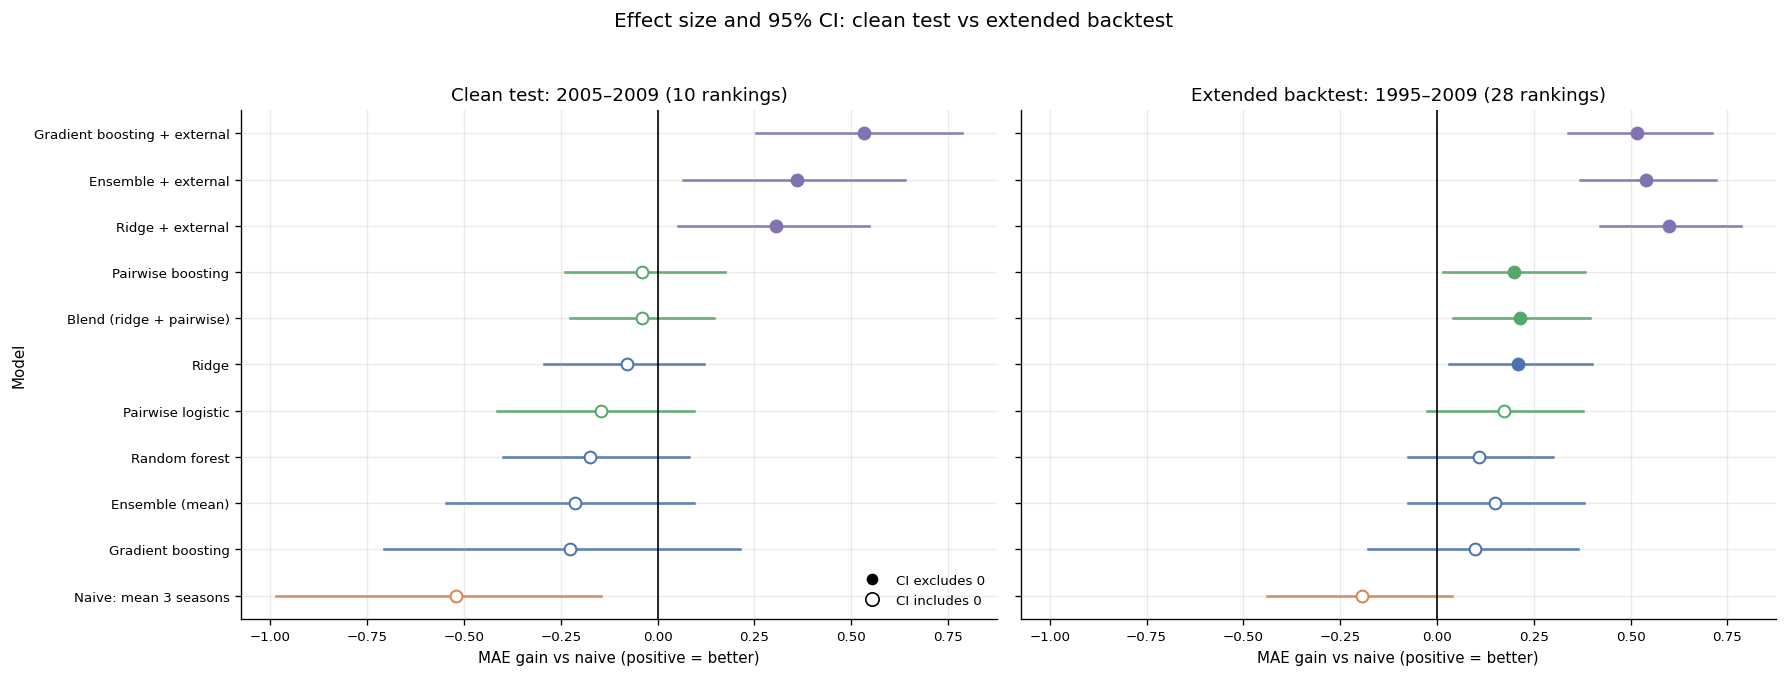

In [13]:
forest_models = (
    significance.drop(index=["Naive: previous season", "Random ranking"])
    .sort_values("mae_gain_vs_naive")
    .index.tolist()
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.6), sharex=True, sharey=True)
for ax, (title, sig_table) in zip(
    axes,
    [
        ("Clean test: 2005–2009 (10 rankings)", significance),
        ("Extended backtest: 1995–2009 (28 rankings)", sig_bt),
    ],
):
    s = sig_table.loc[forest_models]
    y = np.arange(len(s))
    for yi, (name, row) in zip(y, s.iterrows()):
        color = COLORS[FAMILY[name]]
        ax.plot([row["ci_low"], row["ci_high"]], [yi, yi], color=color, lw=1.5, zorder=1)
        face = color if row["significant"] else "white"
        ax.scatter(row["mae_gain_vs_naive"], yi, color=face, edgecolor=color,
                   s=50, linewidth=1.2, zorder=2)
    ax.axvline(0, color="black", lw=1)
    ax.set_yticks(y)
    ax.set_yticklabels(s.index)
    ax.invert_yaxis()
    ax.set_xlabel("MAE gain vs naive (positive = better)")
    ax.set_title(title)
    ax.grid(axis="x", alpha=0.25)

axes[0].set_ylabel("Model")
handles = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor="black", markersize=8,
           label="CI excludes 0"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="white",
           markeredgecolor="black", markersize=8, label="CI includes 0"),
]
axes[0].legend(handles=handles, loc="lower right", frameon=False)
fig.suptitle("Effect size and 95% CI: clean test vs extended backtest", y=1.00)
plt.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

## 11. Verdict

The cell below prints the automatic verdict: best overall model, best model per family, significance
against the naive baseline, and whether the pairwise / roster formulations add something over the
team-only Ridge.

In [14]:
best_team = family_best.loc[family_best["family"] == "Team history"].index[0]
best_pairwise = family_best.loc[family_best["family"] == "Pairwise"].index[0]
best_external = family_best.loc[family_best["family"] == "External"].index[0]

print("BEST MODEL PER FAMILY")
for _, row in family_best.iterrows():
    print(f"  {row['family']:14s} {row.name:30s} MAE {row['mae']:.3f} | "
          f"Spearman {row['spearman']:.3f} | top-8 {row['top_overlap']:.0%}")

print("\nBEST OVERALL")
s = summary.loc[best_overall]
print(f"  {best_overall}: MAE {s['mae']:.3f} | Spearman {s['spearman']:.3f} | "
      f"top-8 {s['top_overlap']:.0%} | pair accuracy {s['pair_accuracy']:.1%}")
print(f"  gain vs naive: {s['mae_gain_vs_naive']:+.3f} positions, "
      f"95% CI [{s['ci_low']:+.3f}, {s['ci_high']:+.3f}]")
print(f"  skill vs random ranking: {1 - s['mae'] / random_mae:.0%} of the random error removed")

if s["significant"]:
    print("  -> The model is reliably better than the naive baseline.")
else:
    print("  -> The gain over the naive baseline is NOT statistically established on these seasons.")

print("\nDOES THE EXTRA FORMULATION ADD SOMETHING?")
for name, ref, label in [
    (best_pairwise, best_team, "best pairwise vs best team-history"),
    (best_external, best_team, "best external vs best team-history"),
    (best_external, best_pairwise, "best external vs best pairwise"),
]:
    rec = head_to_head[(head_to_head["model"] == name) & (head_to_head["opponent"] == ref)].iloc[0]
    verdict = "significant" if rec["better"] else "within noise"
    print(f"  {label}: {rec['gain']:+.3f} positions "
          f"[{rec['ci_low']:+.3f}, {rec['ci_high']:+.3f}] -> {verdict}")

evaluated_models = summary.drop(index=["Random ranking"])
evaluated_models = evaluated_models[evaluated_models["family"] != "Naive"]
n_sig = int(evaluated_models["significant"].sum())
print(f"\nModels significantly better than the naive baseline: {n_sig} / {len(evaluated_models)}")

bt = summary_bt.loc[bt_best]
print("\nEXTENDED BACKTEST (1995–2009, 28 rankings)")
print(f"  {bt_best}: MAE {bt['mae']:.3f} | gain vs naive {bt['mae_gain_vs_naive']:+.3f} "
      f"[{bt['ci_low']:+.3f}, {bt['ci_high']:+.3f}] -> "
      f"{'significant' if bt['significant'] else 'within noise'}")
print("  Reminder: 1995–2004 was used for feature selection; this is a stability/power check, "
      "not a clean out-of-sample test.")

BEST MODEL PER FAMILY
  Naive          Naive: previous season         MAE 3.387 | Spearman 0.486 | top-8 64%
  Team history   Ridge                          MAE 3.467 | Spearman 0.481 | top-8 57%
  Pairwise       Pairwise boosting              MAE 3.427 | Spearman 0.495 | top-8 60%
  External       Gradient boosting + external   MAE 2.853 | Spearman 0.583 | top-8 69%

BEST OVERALL
  Gradient boosting + external: MAE 2.853 | Spearman 0.583 | top-8 69% | pair accuracy 71.8%
  gain vs naive: +0.533 positions, 95% CI [+0.253, +0.787]
  skill vs random ranking: 42% of the random error removed
  -> The model is reliably better than the naive baseline.

DOES THE EXTRA FORMULATION ADD SOMETHING?
  best pairwise vs best team-history: +0.040 positions [-0.013, +0.093] -> within noise
  best external vs best team-history: +0.613 positions [+0.347, +0.880] -> significant
  best external vs best pairwise: +0.573 positions [+0.293, +0.840] -> significant

Models significantly better than the naive b

## 12. Notes and limitations

* **Small test sample.** The evaluation covers 5 seasons and 10 conference rankings. The paired
  bootstrap over whole rankings is the right unit, but the intervals remain wide: most differences
  between models are within noise. This is a property of hockey parity and of the short test period,
  not a bug.
* **Naive baseline.** "Previous season" means re-ranking last season's points in the current
  conference. It is the strongest naive history score on the test seasons (see section 9). The
  `mean 3 seasons` baseline is smoother but worse here.
* **Roster assumption.** Roster features use the players who actually played for the team in the
  predicted season, so in-season arrivals are included. Talent values only use the previous season,
  but part of the roster gain may come from in-season trades (good teams buy players). Treat the
  external models as an upper bound rather than a strict day-before-the-season forecast.
* **External data are still internal.** The extra features come from the provided hockey tables
  (shots, goalies, players, coaches, playoffs, awards, splits). Market information — preseason win
  totals, injuries, payroll — is not available and is the next real lever for a larger gain.
* **Feature selection.** The greedy selection uses 1995–2004 only. The clean test is 2005–2009;
  the extended backtest (section 10) is a stability/power check, not a fully clean out-of-sample
  test for the feature selection.
* **Hyper-parameters.** All values are fixed to conservative choices. Tuning on 5 test seasons
  would mostly fit noise.
* **Legacy LSTM.** `archive/ranking_predictions_lstm.ipynb` trains a matchup LSTM on 1998–2003 and
  evaluates 2005–2008 with a different naive baseline (previous conference rank, not previous
  points). Its reported result (MAE 3.94 vs 4.17) is **not directly comparable** with the table above;
  it is kept as a legacy experiment.
* **What is not available.** "Current win streak" (see `Attributs_AC.txt`) cannot be built from
  season-level aggregates; per-game data would be needed.